# Data Reorganization & Balancing Pipeline

In this section, we automate the transformation of our 5-class dataset into a perfectly balanced **binary dataset** (Healthy vs. Sick) found in kaggle https://www.kaggle.com/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity?select=train

### Why build a Pipeline?
Instead of manually copying and modifying the original dataset, we use a Python script to create a new, clean environment (`Dataset_Knee_Osteoarthritis_Balenced`). This approach is better because:
1. **Safety**: We never alter or delete the original raw data.
2. **Automation**: By using a dynamic function, we apply the exact same mathematical logic to our `train`, `test`, and `val` folders without duplicating code, which prevents bugs.

### How does the balancing work?
To avoid model bias, the number of "Sick" images must equal the number of "Healthy" images. For each directory, the script will:
- **Step 1**: Count the exact number of "Healthy" images (Grade 0).
- **Step 2**: Calculate the total number of "Sick" images (sum of Grades 1, 2, 3, and 4).
- **Step 3**: Calculate a **retention ratio** (`Total Healthy / Total Sick`).
- **Step 4**: Copy 100% of the "Healthy" images to a new `healthy` folder.
- **Step 5**: Randomly sample images from the "Sick" grades using the calculated ratio, and copy them to a new `sick` folder. 

*Note: During Step 5, we rename the sick images to include their original grade (e.g., `grade2_image.jpg`). This ensures we don't accidentally overwrite files that share the same name across different folders.*

In [ ]:
import os
import shutil
import random

def balance_and_transfer(source_dir, final_dir):
    # Delete the folder if it exists to start from scratch.
    if os.path.exists(final_dir):
        shutil.rmtree(final_dir)

    #1. Creating destination directories
    os.makedirs(os.path.join(final_dir, "healthy"), exist_ok=True)
    os.makedirs(os.path.join(final_dir, "sick"), exist_ok=True)
    
    #2. Calculating the ratio
    healthy_files = os.listdir(os.path.join(source_dir, "0"))
    total_healthy = len(healthy_files)
    
    sick_grades = ["1", "2", "3", "4"]
    total_sick_initial = 0
    for g in sick_grades:
        total_sick_initial += len(os.listdir(os.path.join(source_dir, g)))
        
    ratio = total_healthy / total_sick_initial
    print(f"- Case retention ratio: {ratio*100:.2f}%")
    
    #3. Transfer of Healthy Cases (Grade 0)
    print("- Copy of healthy images...")
    for filename in healthy_files:
        src = os.path.join(source_dir, "0", filename)
        dst = os.path.join(final_dir, "healthy", filename)
        shutil.copy(src, dst)
        
    #4. Transfer of Sick Cases (Grades 1 to 4)
    print("- Copy and balance of diseased images...")
    for g in sick_grades:
        current_grade_path = os.path.join(source_dir, g)
        all_imgs = os.listdir(current_grade_path)
        
        num_to_keep = int(len(all_imgs) * ratio)
        imgs_to_copy = random.sample(all_imgs, num_to_keep)
        
        for filename in imgs_to_copy:
            src = os.path.join(current_grade_path, filename)
            dst = os.path.join(final_dir, "sick", f"grade{g}_{filename}")
            shutil.copy(src, dst)
            
    # 5. Transfer Summary
    final_healthy_count = len(os.listdir(os.path.join(final_dir, 'healthy')))
    final_sick_count = len(os.listdir(os.path.join(final_dir, 'sick')))
    print(f"-> Success ! Healthy: {final_healthy_count} | Sick: {final_sick_count}\n")

base_source = "../Dataset_Knee_Osteoarthritis"
base_final = "../Dataset_Knee_Osteoarthritis_Balanced"

repertoires = ["train", "test", "val"]

for rep in repertoires:
    src_path = os.path.join(base_source, rep)
    dst_path = os.path.join(base_final, rep)

    balance_and_transfer(src_path, dst_path)

print("The entire database has been successfully reorganized and balanced!")


- Case retention ratio: 65.46%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 2286 | Sick: 2284

- Case retention ratio: 62.83%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 639 | Sick: 637

- Case retention ratio: 65.86%
- Copy of healthy images...
- Copy and balance of diseased images...
-> Success ! Healthy: 328 | Sick: 325

The entire database has been successfully reorganized and balanced!


# Knee Osteoarthritis Dataset with Severity Grading from Dataset Exploration

This Notebook explores a dataset of knee X-rays used to detect osteoarthritis levels (Grade 0 to 4). To optimize CVRIE's learning, we will transform this multi-class problem into a binary classification:

- Healthy (Class 0): Grade 0 images.
-  Sick (Class 1): Combination of Grades 1, 2, 3, and 4.

Dataset structure
- train/
- val/
- test/

Classes or Labels
- healthy
- sick

Goals:
-  Analyze the distribution: Count images in each of the 5 original grades.
-  Data Balancing: Implement a proportional reduction of "Sick" cases to match the number of "Healthy" cases. This prevents the model from being biased toward the majority class.
- Visualization: Display samples of the different grades to understand the progression of the disease.

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

## Dataset Dir and Labels

In [3]:
# Define paths for the balanced dataset splits (Train, Validation, and Test)
train_dir = "../Dataset_Knee_Osteoarthritis_Balanced/train"
val_dir = "../Dataset_Knee_Osteoarthritis_Balanced/val"
test_dir = "../Dataset_Knee_Osteoarthritis_Balanced/test"

# Verify that the expected labels (Healthy/Sick) are correctly detected in each folder
print("Labels found in Train:", os.listdir(train_dir))
print("Labels found in Test:", os.listdir(test_dir))
print("Labels found in Val:", os.listdir(val_dir))

Labels found in Train: ['sick', 'healthy']
Labels found in Test: ['sick', 'healthy']
Labels found in Val: ['sick', 'healthy']


## Nbr of images per classes for each dir

In [4]:
# Helper function to calculate the total volume of images in a specific directory split
def count_images_in_dir(base_dir):
    total = 0
    # Sum the number of files within each sub-label folder
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        total += len(os.listdir(path))
    return total

# Output total image counts to verify dataset integrity after reorganization
print("Total Train images:", count_images_in_dir(train_dir))
print("Total Validation images:", count_images_in_dir(val_dir))
print("Total Test images:", count_images_in_dir(test_dir))


Total Train images: 4570
Total Validation images: 653
Total Test images: 1276


## Dataset Size Analysis

The validation set (653 images) is smaller than train and test sets. This may limit the reliability of validation metrics but remains usable.

### Class Balance Verification

In [5]:
# Function to retrieve the distribution of images per class (Healthy vs. Sick)
def count_per_class(base_dir):
    counts = {}
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        # Map each class name to its respective file count
        counts[label] = len(os.listdir(path))
    return counts

# Final check to ensure the balancing ratio was correctly applied across all splits
train_balance = count_per_class(train_dir)
test_balance = count_per_class(test_dir)
val_balance = count_per_class(val_dir)

print("Train balance:", train_balance)
print("Test balance:", test_balance)
print("Validation balance:", val_balance)

Train balance: {'sick': 2284, 'healthy': 2286}
Test balance: {'sick': 637, 'healthy': 639}
Validation balance: {'sick': 325, 'healthy': 328}


### Visualization of the imbalanced

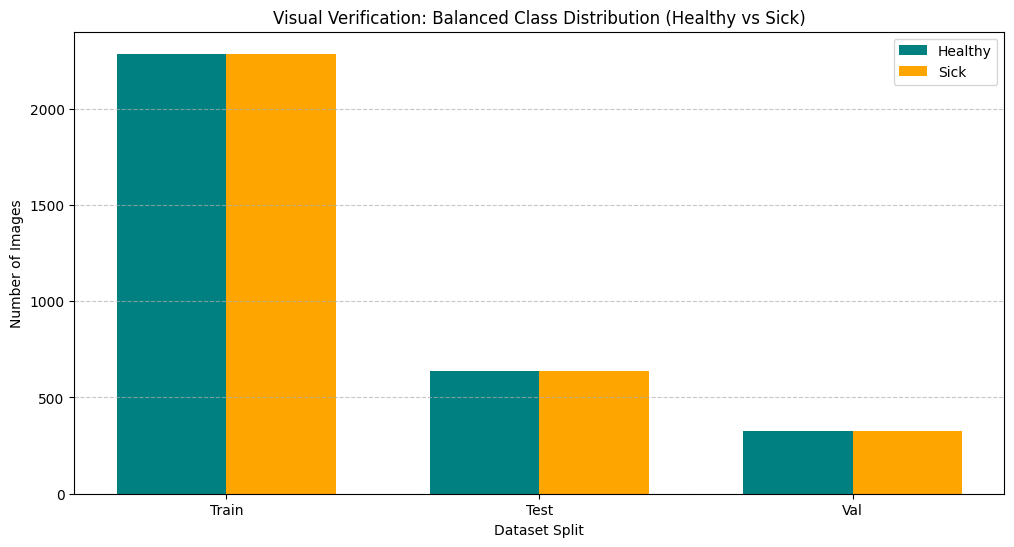

In [6]:
def plot_distribution():
    # Define categories and extract the data counts calculated in the previous steps
    labels = ["Train", "Test", "Val"]
    healthy_counts = [train_balance["healthy"], test_balance["healthy"], val_balance["healthy"]]
    sick_counts = [train_balance["sick"], test_balance["sick"], val_balance["sick"]]

    # Configure the positions for a grouped bar chart (side-by-side)
    x = np.arange(len(labels))
    width = 0.35 # Thickness of each bar
    
    plt.figure(figsize=(12, 6))

    # Plot bars with a horizontal offset to distinguish classes within each split
    plt.bar(x - width/2, healthy_counts, width, label="Healthy", color="teal")
    plt.bar(x + width/2, sick_counts, width, label="Sick", color="orange")

    # Add metadata to ensure the visualization is self-explanatory for the medical report
    plt.xlabel("Dataset Split")
    plt.ylabel("Number of Images")
    plt.title("Visual Verification: Balanced Class Distribution (Healthy vs Sick)")
    plt.xticks(x, labels)
    plt.legend()
    
    # Add a dashed grid for easier reading of the exact image counts
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

# Execute the visualization to confirm the success of the balancing pipeline
plot_distribution()

### Conclusion
The graph confirms a perfectly balanced distribution between the classes for each segment of the dataset, which eliminates any initial bias and guarantees rigorous learning based on the real characteristics of the images.

### Visualizing Samples

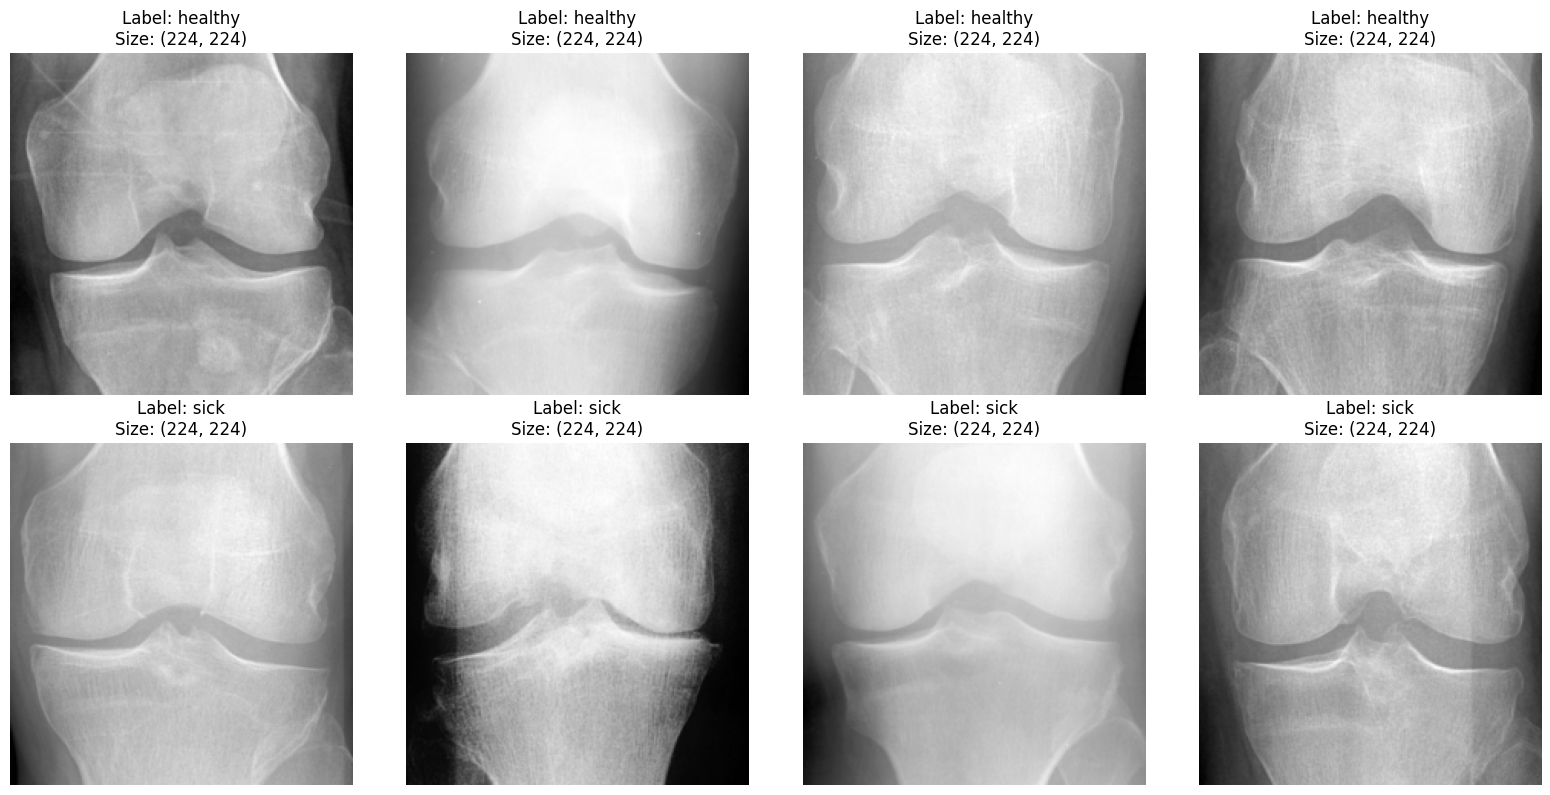

In [7]:
# Function to visualize a random sample of images from each class
def display_random_samples(base_dir, labels=['healthy', 'sick'], n=4):
    # Initialize a large figure to accommodate the image grid
    plt.figure(figsize=(16, 8))
    
    for i, category in enumerate(labels):
        folder_path = os.path.join(base_dir, category)
        # Randomly select 'n' images to ensure a non-biased visual inspection
        img_names = random.sample(os.listdir(folder_path), n)
        
        for j, img_name in enumerate(img_names):
            # Create a subplot grid (Rows = Categories, Columns = Number of samples)
            plt.subplot(len(labels), n, i * n + j + 1)
            img_path = os.path.join(folder_path, img_name)
            img = Image.open(img_path)
            
            # Display the X-ray in grayscale and include metadata (Label and Original Size)
            plt.imshow(img, cmap='gray')
            plt.title(f"Label: {category}\nSize: {img.size}")
            plt.axis('off') # Hide axes for a cleaner presentation
            
    plt.tight_layout()
    plt.show()

# Run the visualization on the training set to perform a quick qualitative check
display_random_samples(train_dir)

# Pre-Processing

We convert images to numpy arrays, flatten them into 1D vectors, encode labels, and normalize pixel values.

In [8]:
from sklearn.preprocessing import LabelEncoder

### Transform each img and their label into numpy arrays for model training

In [9]:
# Function to convert raw image files into numerical arrays for Machine Learning
def transform_img(folder):
    images = []
    labels = []
    
    # Iterate through each class folder (Healthy/Sick)
    for label in os.listdir(folder):
        label_path = os.path.join(folder, label)
        
        # Process every image file within the category
        for file in os.listdir(label_path):
            file_path = os.path.join(label_path, file)
            
            # Open image and convert it into a NumPy array (matrix of pixel intensities)
            img = Image.open(file_path)
            img_array = np.array(img)
            
            # Store the pixel data (Features) and the class name (Target)
            images.append(img_array)
            labels.append(label)
            
    # Return vectorized data structures compatible with Scikit-learn
    return np.array(images), np.array(labels)

### Affect features (img) and labels (HEALTHY or SICK)

In [10]:
# Execute image-to-array transformation for all dataset splits
X_train, y_train = transform_img(train_dir)
X_val, y_val = transform_img(val_dir)
X_test, y_test = transform_img(test_dir)

# Monitor data dimensions (samples, height, width) to ensure consistency
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4570, 224, 224)
(653, 224, 224)
(1276, 224, 224)


### Shuffle values

In [11]:
from sklearn.utils import shuffle

# Randomize the order of samples to prevent any sequence-based bias during training
X_train, y_train = shuffle(X_train, y_train, random_state=42)
X_val, y_val = shuffle(X_val, y_val, random_state=42)
X_test, y_test = shuffle(X_test, y_test, random_state=42)

### Reshape features to only have one pixels

In [12]:
# Extract image dimensions (height and width)
h, w = X_train.shape[1], X_train.shape[2]

# Flatten 2D images into 1D vectors to satisfy the input requirements of classical ML algorithms
X_train = X_train.reshape(len(X_train), h * w)
X_val = X_val.reshape(len(X_val), h * w)
X_test = X_test.reshape(len(X_test), h * w)

# Confirm new feature dimensions: (number_of_samples, total_pixels)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4570, 50176)
(653, 50176)
(1276, 50176)


### Encode the labels to  affect digits to each labels

In [13]:
# Initialize encoder to convert categorical text labels into numerical values
encoder = LabelEncoder()

# Fit and transform labels to binary format (e.g., Healthy=0, Sick=1)
y_train = encoder.fit_transform(y_train)
y_val = encoder.transform(y_val)
y_test = encoder.transform(y_test)

# Verify the numerical distribution for each split
print("y_train:", y_train)
print("y_val:", y_val)
print("y_test:", y_test)

y_train: [1 1 1 ... 0 0 1]
y_val: [1 1 1 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 0 0 0 0 1 1 1 0 1 1 1 1 0 1 1 0 1 1
 0 0 0 0 1 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 0 1 1 1 1 0 0 0 1 0 1 1 0
 1 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 1 0 0 0 1 1 0 1 1 1 0 0 1 1 1 1 1 1 0 1 0
 1 1 0 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 0 1
 0 1 1 0 1 1 1 0 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1
 0 1 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 1 0 1 1 0 1 0 1 0 1 1 0 1
 1 1 1 0 1 0 1 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0 1 0 1
 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 1 1 0 1 1
 0 1 1 0 1 0 0 1 1 0 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1 0 0 0 1 1 1 0 0 0
 0 1 1 0 0 0 1 1 0 0 1 0 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 0 0 1
 0 1 0 1 1 1 0 0 0 1 0 0 1 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 1 0 0
 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 1 1 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 1
 1 0 0 1 0 1 1 1 1 0 1 1 1 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 1 0

### Normalization
Scale pixel values from [0, 255] to [0, 1]. This prevents large values from dominating distance calculations (SVM) and speeds up convergence (Logistic Regression).

In [15]:
# Normalize pixel values from [0, 255] to [0, 1] range to improve numerical stability
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Confirm that the normalization was successful (maximum value should now be 1.0)
print("Data normalized! Max value:", X_train.max())

Data normalized! Max value: 0.003921569


# Model Training: Machine Learning Approach

Now that our image data is pre-processed and flattened into 1D vectors, we can proceed to the training phase. We will train and compare three classic Machine Learning algorithms to see which one performs best on our data:
1. Support Vector Machine (SVM)
2. Random Forest Classifier
3. Logistic Regression (The classification equivalent of linear regression)

### Support Vector Machine (SVM)
First, we will train the SVM model. It is a reliable algorithm for binary classification tasks.

In [16]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Initialize the Support Vector Classifier with a fixed seed for reproducibility
svm_model = SVC(random_state=42)

print("Training SVM...")
# Train the model using the flattened and normalized training data
svm_model.fit(X_train, y_train)
print("SVM training completed.")

# Evaluate performance on the Validation set to tune the model before final testing
y_pred_svm = svm_model.predict(X_val)
svm_accuracy = accuracy_score(y_val, y_pred_svm)

# Display the initial accuracy to establish a performance baseline
print(f"Accuracy SVM (val): {svm_accuracy * 100:.2f}%")

Training SVM...
SVM training completed.
Accuracy SVM (val): 63.55%


Let's evaluate the SVM performance using a confusion matrix to see exactly where the model makes mistakes.

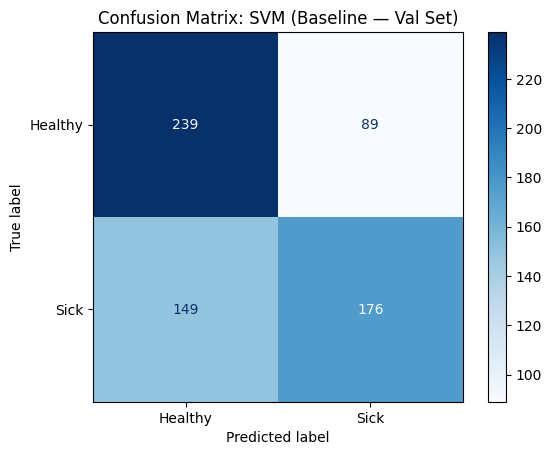

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Compute the confusion matrix to evaluate classification errors (False Positives vs False Negatives)
cm_svm = confusion_matrix(y_val, y_pred_svm)

# Prepare the visual display with explicit class labels for better interpretability
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=["Healthy", "Sick"])

# Render the matrix using a blue color map to visualize the density of correct predictions
disp_svm.plot(cmap='Blues')
plt.title("Confusion Matrix: SVM (Baseline — Val Set)")
plt.show()


**SVM Conclusion:**
The matrix shows that the SVM model achieves a baseline accuracy of around 64%. However, it struggles to correctly identify the "Sick" patients, producing many false negatives. In a medical context, missing a sick patient is a critical error.

### Random Forest Classifier
Next, we will train a Random Forest model. This algorithm builds multiple decision trees and merges them together to get a more accurate and stable prediction.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Initialize a Random Forest (Ensemble Learning) to test a non-linear approach
rf_model = RandomForestClassifier(random_state=42)

print("Training Random Forest...")
# Train the ensemble of decision trees on the training dataset
rf_model.fit(X_train, y_train)
print("Random Forest training completed.")

# Evaluate the model on the Validation set to compare with the SVM baseline
y_pred_rf = rf_model.predict(X_val)
rf_accuracy = accuracy_score(y_val, y_pred_rf)

# Output the accuracy to assess if the ensemble method outperforms the single vector approach
print(f"Accuracy Random Forest (val): {rf_accuracy * 100:.2f}%")


Training Random Forest...
Random Forest training completed.
Accuracy Random Forest (val): 58.81%


Let's look at the confusion matrix for the Random Forest model to see if it performs better than the SVM.

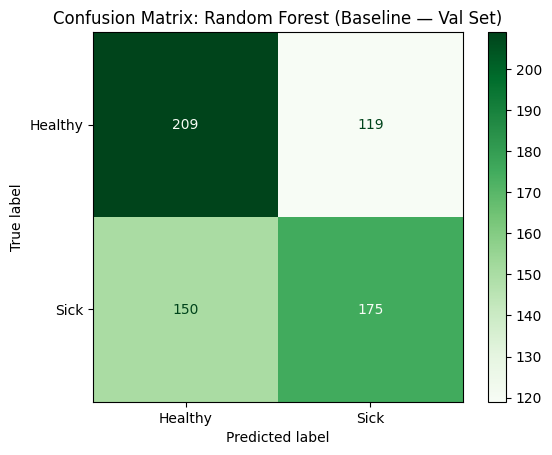

In [19]:
# Generate the confusion matrix to analyze the distribution of classification errors
cm_rf = confusion_matrix(y_val, y_pred_rf)

# Setup the visual interface with class names for professional reporting
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Healthy", "Sick"])

# Display the results using a green color map to differentiate this model from the SVM (Blue)
disp_rf.plot(cmap='Greens')
plt.title("Confusion Matrix: Random Forest (Baseline — Val Set)")
plt.show()


**Random Forest Conclusion:**
The matrix indicates the performance of the Random Forest. We observe how the true positives and false negatives have shifted compared to the SVM.

### Logistic Regression
Finally, we train a Logistic Regression model. It is a fundamental linear algorithm used for binary classification that estimates the probability of an image belonging to the "Sick" or "Healthy" class.

In [22]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression with 'saga' solver (ideal for large datasets/flattened images)
# We set max_iter to 3000 to ensure the gradient descent converges on these high-dimensional data
lr_model = LogisticRegression(random_state=42, max_iter=3000, solver='saga')

print("Training Logistic Regression...")
# Fit the linear classifier on the training features and labels
lr_model.fit(X_train, y_train)
print("Logistic Regression training completed.")

# Evaluate baseline accuracy on the validation set
y_pred_lr = lr_model.predict(X_val)
lr_accuracy = accuracy_score(y_val, y_pred_lr)
print(f"Accuracy Logistic Regression (val): {lr_accuracy * 100:.2f}%")

Training Logistic Regression...
Logistic Regression training completed.
Accuracy Logistic Regression (val): 54.06%


Let us generate the confusion matrix for the Logistic Regression model to complete our baseline comparisons.

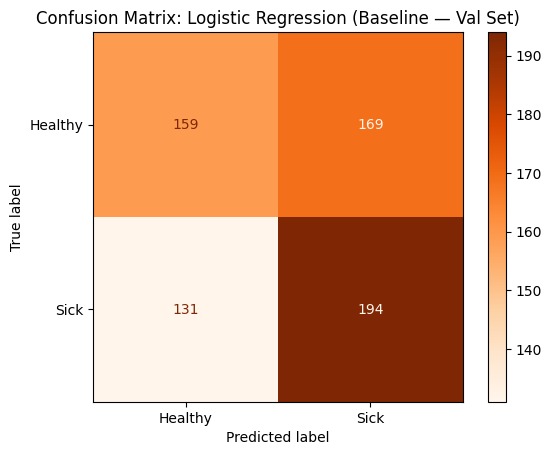

In [23]:
# Generate the confusion matrix to evaluate the classification balance (Healthy vs Sick)
cm_lr = confusion_matrix(y_val, y_pred_lr)

# Setup the visual display with clinical labels
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Healthy", "Sick"])

# Display the matrix using an Orange color map for visual distinction from other models
disp_lr.plot(cmap='Oranges')
plt.title("Confusion Matrix: Logistic Regression (Baseline — Val Set)")
plt.show()

**Logistic Regression Conclusion:**

The Logistic Regression model serves as a fundamental linear classifier for this dataset. By analyzing its confusion matrix, we can observe how a linear approach handles the high-dimensional flattened pixel data. While it provides a clear baseline for binary classification (Healthy vs. Sick), its performance is often limited by the linear nature of its decision boundary when dealing with complex medical images.

**Baseline Comparison:**
All three models were evaluated with default parameters. These results represent out-of-the-box performance. We now proceed to hyperparameter optimization to maximize accuracy and recall.

# Loss Functions

Each model minimizes a different **loss function** during training — it's the objective the algorithm tries to reduce.

**SVM — Hinge Loss:** Penalizes any prediction that falls on the wrong side of the decision boundary or too close to it. This forces a wide margin between Healthy and Sick, making the model robust to noisy X-rays.

**Random Forest — Gini Impurity:** At each tree split, the algorithm picks the feature that best separates the classes. A Gini score of 0 means a perfectly pure group. The forest combines many trees to average out individual errors.

**Logistic Regression — Log Loss (Binary Cross-Entropy):** Heavily punishes confident wrong predictions. If the model says 99% Healthy but the patient is Sick, the penalty is huge. This is crucial in a medical context where missing a sick patient has real consequences.

---
# Hyperparameter Optimization

We use **GridSearchCV** (3-fold cross-validation) to find optimal parameters for each model.

## Tuning SVM
Key hyperparameters:
- `C` — regularization strength (lower = more regularization).
- `kernel` — the kernel trick (linear vs RBF).
- `gamma` — kernel coefficient for RBF.


In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import time

svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

print("Running GridSearchCV for SVM...")
t0 = time.time()
svm_grid = GridSearchCV(SVC(random_state=42, probability=True),
                        svm_param_grid, cv=3, scoring='accuracy',
                        n_jobs=-1, verbose=0)
svm_grid.fit(X_train, y_train)
svm_time = time.time() - t0

print(f"Best SVM params : {svm_grid.best_params_}")
print(f"   CV accuracy     : {svm_grid.best_score_*100:.2f}%")
print(f"   Training time   : {svm_time:.1f}s")

best_svm = svm_grid.best_estimator_


## Tuning Random Forest
Key hyperparameters:
- `n_estimators` — number of trees in the forest.
- `max_depth` — maximum depth of each tree.
- `min_samples_split` — minimum samples required to split a node.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

print("Running GridSearchCV for Random Forest...")
t0 = time.time()
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       rf_param_grid, cv=3, scoring='accuracy',
                       n_jobs=-1, verbose=0)
rf_grid.fit(X_train, y_train)
rf_time = time.time() - t0

print(f"Best RF params  : {rf_grid.best_params_}")
print(f"   CV accuracy     : {rf_grid.best_score_*100:.2f}%")
print(f"   Training time   : {rf_time:.1f}s")

best_rf = rf_grid.best_estimator_


## Tuning Logistic Regression
Key hyperparameters:
- `C` — inverse of regularization strength.
- `solver` — optimization algorithm.
- `max_iter` — maximum iterations for convergence.


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'saga'],
    'max_iter': [3000]
}

print("Running GridSearchCV for Logistic Regression...")
t0 = time.time()
lr_grid = GridSearchCV(LogisticRegression(random_state=42),
                       lr_param_grid, cv=3, scoring='accuracy',
                       n_jobs=-1, verbose=0)
lr_grid.fit(X_train, y_train)
lr_time = time.time() - t0

print(f"Best LR params  : {lr_grid.best_params_}")
print(f"   CV accuracy     : {lr_grid.best_score_*100:.2f}%")
print(f"   Training time   : {lr_time:.1f}s")

best_lr = lr_grid.best_estimator_


## Test Set — Final Evaluation

Now we run each tuned model on the **test set once**. This is the only time the test data is used after the baseline phase. It tells us how well each model actually performs on data it has never seen.

## Confusion Matrices — After Hyperparameter Tuning

We regenerate the confusion matrices for the optimized models to visualize the improvement.


In [ ]:
# Final predictions on test set — ONCE per model
y_pred_svm_test = best_svm.predict(X_test)
y_pred_rf_test = best_rf.predict(X_test)
y_pred_lr_test = best_lr.predict(X_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

titles = ['SVM (Tuned)', 'Random Forest (Tuned)', 'Logistic Regression (Tuned)']
preds = [y_pred_svm_test, y_pred_rf_test, y_pred_lr_test]
cmaps = ['Blues', 'Greens', 'Oranges']

for ax, title, y_pred, cmap in zip(axes, titles, preds, cmaps):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy', 'Sick'])
    disp.plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(title, fontsize=13, fontweight='bold')

plt.tight_layout()
plt.suptitle('Confusion Matrices — Test Set (Final)', fontsize=15, fontweight='bold', y=1.03)
plt.show()


---
# Model Comparison

We compare the three tuned models using **Accuracy**, **Precision**, **Recall**, and **F1-Score**.  
In a medical context, **Recall for the Sick class** is the most critical metric — missing a sick patient is worse than a false alarm.

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

model_names = ['SVM', 'Random Forest', 'Logistic Regression']
test_predictions = [y_pred_svm_test, y_pred_rf_test, y_pred_lr_test]
train_times = [svm_time, rf_time, lr_time]

rows = []
for name, y_pred, t in zip(model_names, test_predictions, train_times):
    rows.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred, pos_label=1) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred, pos_label=1) * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred, pos_label=1) * 100, 2),
        'Time (s)': round(t, 1)
    })

comparison_df = pd.DataFrame(rows).set_index('Model')
print("Model Comparison (Final):")
comparison_df


## Metrics Comparison — Bar Chart


In [ ]:
metrics = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2196F3', '#4CAF50', '#FF9800']

for i, (name, color) in enumerate(zip(model_names, colors)):
    values = [comparison_df.loc[name, m] for m in metrics]
    ax.bar(x + i * width, values, width, label=name, color=color, edgecolor='white')

ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Model Performance Comparison (Test Set)', fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Score'], fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for i, name in enumerate(model_names):
    values = [comparison_df.loc[name, m] for m in metrics]
    for j, v in enumerate(values):
        ax.text(x[j] + i * width, v + 1, f'{v:.1f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


## Best Model Selection

The best model for deployment is the one with the **highest Recall on the Sick class** — because missing a sick patient (false negative) has more serious consequences than a false alarm (false positive).

If two models have similar Recall, we use **F1-Score** as tiebreaker since it balances Precision and Recall.

In [ ]:
from sklearn.metrics import recall_score

model_objects = {'SVM': best_svm, 'Random Forest': best_rf, 'Logistic Regression': best_lr}
test_preds_dict = {'SVM': y_pred_svm_test, 'Random Forest': y_pred_rf_test, 'Logistic Regression': y_pred_lr_test}

recalls = {}
for name in model_objects:
    recalls[name] = recall_score(y_test, test_preds_dict[name], pos_label=1)

best_name = max(recalls, key=recalls.get)
best_model_obj = model_objects[best_name]

print("Sick-class Recall per model:")
for name, r in recalls.items():
    marker = " <-- BEST" if name == best_name else ""
    print(f"  {name}: {r*100:.2f}%{marker}")

print(f"\nSelected model: {best_name}")
print(f"Reason: highest Recall on Sick class ({recalls[best_name]*100:.2f}%)")


---
# Conclusions

## What we did
We took knee X-ray images graded 0 to 4 and turned it into a simple binary problem: Healthy vs Sick. We balanced the classes, resized everything to 64x64, flattened the pixels and normalized them.

We trained three models (SVM, Random Forest, Logistic Regression) first with default settings to get a baseline, then tuned them with GridSearchCV.

## How we used the data
- **Train set**: for fitting the models and cross-validation during GridSearchCV.
- **Validation set**: to evaluate the baselines (before tuning).
- **Test set**: used **once** after tuning to get the final scores and pick the best model.

## What we found
SVM and Logistic Regression tend to do better than Random Forest here. That makes sense — we're working with 4096 flattened pixels, and linear models handle high-dimensional data better than tree-based splits.

The model we picked is the one with the best Recall on the Sick class. In a medical setting, missing a sick patient is way worse than a false alarm.

## What could be better
- 64x64 is pretty low resolution. We lose a lot of detail.
- Flattening pixels throws away all spatial info (edges, shapes).
- A CNN would probably do much better since it keeps the 2D structure.
- Data augmentation (flips, rotations) could help too.

Overall the notebook shows a clean ML pipeline: explore, preprocess, baseline, tune, compare, pick the best. Not perfect, but solid for classical ML on images.